# Classical Machine Learning Models

## TRUST-XIDS — Notebook 4

Trains and compares the three mandatory classical models — **Random
Forest**, **XGBoost**, and **Support Vector Machine** — using the
redundancy-trimmed full-feature sets and the harmonized cross-dataset
feature set from Notebook 3.

Same three experiment types for every model, so results stay directly
comparable:

- **Within-dataset (full features):** train and test on UNSW-NB15 using
  its own selected feature set, then the same for CICIDS2017.
- **Within-dataset (harmonized features):** same splits, only the 8 common
  features — shows how much performance is lost by dropping dataset-specific
  columns like `sttl` and `ct_srv_dst`.
- **Cross-dataset (harmonized features):** train on one dataset's
  harmonized training set, test on the other's harmonized test set. Given
  Notebook 3's KS statistics (every harmonized feature differs substantially
  between the two datasets), a performance drop here is an expected finding,
  not a bug — reported honestly either way.

A SHAP/LIME explainability pass is **not** included here — Notebook 6 does
that, and does it against the full UNSW-NB15 feature set specifically
(not the harmonized cross-dataset set), so the explanations aren't diluted
by the smaller shared schema.

# 1. Import Libraries

In [1]:
import os
import json
import time

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

BASE_DIR = r"C:\Users\Anu\OneDrive\Desktop\IDS"
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
MODELS_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


# 2. Load Selected and Harmonized Datasets

In [2]:
with open(os.path.join(PROCESSED_DIR, "feature_metadata.json")) as f:
    feature_metadata = json.load(f)

unsw_feature_cols = feature_metadata["unsw_final_feature_cols"]
cic_feature_cols = feature_metadata["cic_final_feature_cols"]
common_feature_cols = feature_metadata["common_feature_cols"]

unsw_train = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_train_selected.csv"))
unsw_test = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_test_selected.csv"))
cic_train = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_train_selected.csv"))
cic_test = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_test_selected.csv"))

unsw_train_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_train_harmonized.csv"))
unsw_test_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_test_harmonized.csv"))
cic_train_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_train_harmonized.csv"))
cic_test_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_test_harmonized.csv"))

print("UNSW full-feature train :", unsw_train.shape, " | harmonized train:", unsw_train_harm.shape)
print("CICIDS full-feature train:", cic_train.shape, " | harmonized train:", cic_train_harm.shape)

UNSW full-feature train : (175341, 35)  | harmonized train: (175341, 9)
CICIDS full-feature train: (2016542, 58)  | harmonized train: (2016542, 9)


In [3]:
X_unsw_train = unsw_train[unsw_feature_cols]
y_unsw_train = unsw_train["label"]
X_unsw_test = unsw_test[unsw_feature_cols]
y_unsw_test = unsw_test["label"]

X_cic_train = cic_train[cic_feature_cols]
y_cic_train = cic_train["label"]
X_cic_test = cic_test[cic_feature_cols]
y_cic_test = cic_test["label"]

X_unsw_train_harm = unsw_train_harm[common_feature_cols]
y_unsw_train_harm = unsw_train_harm["label"]
X_unsw_test_harm = unsw_test_harm[common_feature_cols]
y_unsw_test_harm = unsw_test_harm["label"]

X_cic_train_harm = cic_train_harm[common_feature_cols]
y_cic_train_harm = cic_train_harm["label"]
X_cic_test_harm = cic_test_harm[common_feature_cols]
y_cic_test_harm = cic_test_harm["label"]

print("Feature matrices prepared.")

Feature matrices prepared.


# 3. Evaluation Helper

One consistent evaluation routine for every model/experiment combination —
avoids retyping the same six metrics and a confusion matrix plot a dozen
times, and guarantees every experiment is scored the same way.

In [4]:
all_results = []

def evaluate_and_record(model, X_test, y_test, model_name, experiment_name, train_seconds, plot=True, zero_division=0):
    start = time.time()
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    predict_seconds = time.time() - start

    metrics = {
        "model": model_name,
        "experiment": experiment_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=zero_division),
        "recall": recall_score(y_test, y_pred, zero_division=zero_division),
        "f1": f1_score(y_test, y_pred, zero_division=zero_division),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "train_seconds": round(train_seconds, 2),
        "predict_seconds": round(predict_seconds, 4),
    }

    print(f"{model_name} - {experiment_name}")
    for k in ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]:
        print(f"  {k:18s}: {round(metrics[k], 4)}")
    print("  train time (s)    :", metrics["train_seconds"])
    print()
    print(classification_report(y_test, y_pred, target_names=["Normal", "Attack"], zero_division=zero_division))

    if plot:
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
        plt.title(f"{model_name}: {experiment_name}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()

    all_results.append(metrics)
    return metrics

print("Evaluation helper defined.")

Evaluation helper defined.


# 4. Random Forest

Settings fixed across every experiment for a fair comparison:
`n_estimators=100`, `random_state=42`, `n_jobs=-1`. Random Forest needs no
feature scaling.

Random Forest - UNSW full features (within-dataset)
  accuracy          : 0.8658
  balanced_accuracy : 0.8539
  precision         : 0.8188
  recall            : 0.9713
  f1                : 0.8885
  roc_auc           : 0.9752
  train time (s)    : 48.99

              precision    recall  f1-score   support

      Normal       0.95      0.74      0.83     37000
      Attack       0.82      0.97      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.89      0.85      0.86     82332
weighted avg       0.88      0.87      0.86     82332



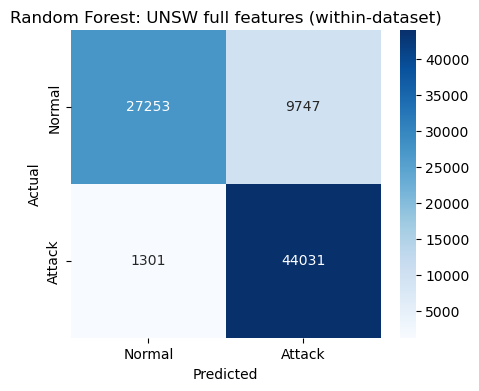

{'model': 'Random Forest',
 'experiment': 'UNSW full features (within-dataset)',
 'accuracy': 0.8658115920905601,
 'balanced_accuracy': 0.8539340970282909,
 'precision': 0.818754881178177,
 'recall': 0.9713006264890144,
 'f1': 0.8885278982948239,
 'roc_auc': 0.975194247366576,
 'train_seconds': 48.99,
 'predict_seconds': 2.1052}

In [5]:
rf_settings = dict(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

# Within-dataset: UNSW full features
t0 = time.time()
rf_unsw = RandomForestClassifier(**rf_settings)
rf_unsw.fit(X_unsw_train, y_unsw_train)
t_unsw = time.time() - t0
evaluate_and_record(rf_unsw, X_unsw_test, y_unsw_test, "Random Forest", "UNSW full features (within-dataset)", t_unsw)

Random Forest - CICIDS full features (within-dataset)
  accuracy          : 0.9986
  balanced_accuracy : 0.9973
  precision         : 0.9964
  recall            : 0.9954
  f1                : 0.9959
  roc_auc           : 0.9998
  train time (s)    : 837.62

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    419001
      Attack       1.00      1.00      1.00     85148

    accuracy                           1.00    504149
   macro avg       1.00      1.00      1.00    504149
weighted avg       1.00      1.00      1.00    504149



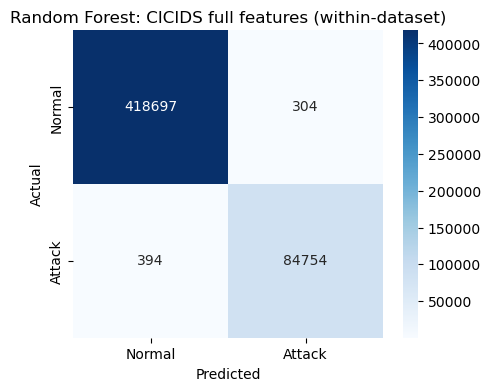

{'model': 'Random Forest',
 'experiment': 'CICIDS full features (within-dataset)',
 'accuracy': 0.9986154886749751,
 'balanced_accuracy': 0.997323613728889,
 'precision': 0.9964259681629006,
 'recall': 0.9953727627190304,
 'f1': 0.9958990869887078,
 'roc_auc': 0.999772869539627,
 'train_seconds': 837.62,
 'predict_seconds': 12.8743}

In [6]:
# Within-dataset: CICIDS full features
t0 = time.time()
rf_cic = RandomForestClassifier(**rf_settings)
rf_cic.fit(X_cic_train, y_cic_train)
t_cic = time.time() - t0
evaluate_and_record(rf_cic, X_cic_test, y_cic_test, "Random Forest", "CICIDS full features (within-dataset)", t_cic)

Random Forest - UNSW harmonized (within-dataset)
  accuracy          : 0.8684
  balanced_accuracy : 0.8574
  precision         : 0.825
  recall            : 0.9659
  f1                : 0.8899
  roc_auc           : 0.9647
  train time (s)    : 27.7

              precision    recall  f1-score   support

      Normal       0.95      0.75      0.84     37000
      Attack       0.82      0.97      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.89      0.86      0.86     82332
weighted avg       0.88      0.87      0.87     82332



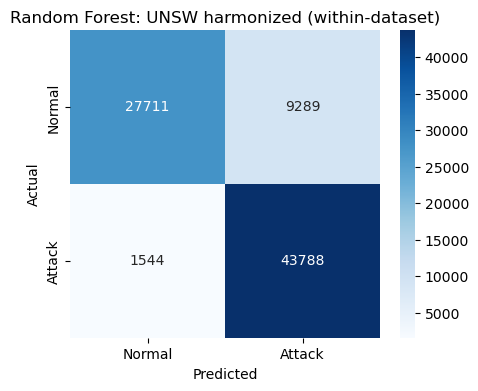

{'model': 'Random Forest',
 'experiment': 'UNSW harmonized (within-dataset)',
 'accuracy': 0.8684229704124763,
 'balanced_accuracy': 0.8574430603284835,
 'precision': 0.8249901087099873,
 'recall': 0.9659401747110209,
 'f1': 0.8899186050056396,
 'roc_auc': 0.9647209885147654,
 'train_seconds': 27.7,
 'predict_seconds': 2.2116}

In [7]:
# Within-dataset: harmonized features (both datasets) - models reused in Section for cross-dataset below
t0 = time.time()
rf_unsw_harm = RandomForestClassifier(**rf_settings)
rf_unsw_harm.fit(X_unsw_train_harm, y_unsw_train_harm)
t_unsw_harm = time.time() - t0
evaluate_and_record(rf_unsw_harm, X_unsw_test_harm, y_unsw_test_harm, "Random Forest", "UNSW harmonized (within-dataset)", t_unsw_harm)

Random Forest - CICIDS harmonized (within-dataset)
  accuracy          : 0.9956
  balanced_accuracy : 0.9918
  precision         : 0.9877
  recall            : 0.986
  f1                : 0.9869
  roc_auc           : 0.9973
  train time (s)    : 415.0

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    419001
      Attack       0.99      0.99      0.99     85148

    accuracy                           1.00    504149
   macro avg       0.99      0.99      0.99    504149
weighted avg       1.00      1.00      1.00    504149



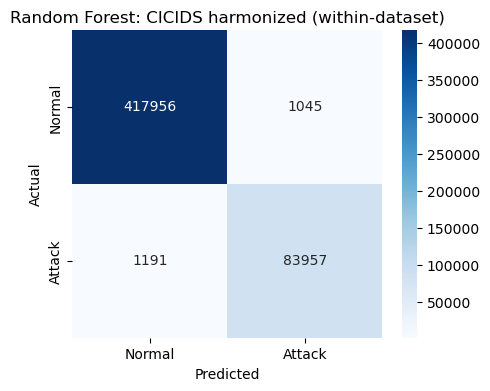

{'model': 'Random Forest',
 'experiment': 'CICIDS harmonized (within-dataset)',
 'accuracy': 0.9955648032625275,
 'balanced_accuracy': 0.9917592811915058,
 'precision': 0.9877061716194913,
 'recall': 0.9860125898435665,
 'f1': 0.98685865412871,
 'roc_auc': 0.9973315290029044,
 'train_seconds': 415.0,
 'predict_seconds': 11.5299}

In [8]:
t0 = time.time()
rf_cic_harm = RandomForestClassifier(**rf_settings)
rf_cic_harm.fit(X_cic_train_harm, y_cic_train_harm)
t_cic_harm = time.time() - t0
evaluate_and_record(rf_cic_harm, X_cic_test_harm, y_cic_test_harm, "Random Forest", "CICIDS harmonized (within-dataset)", t_cic_harm)

Random Forest - Train UNSW, test CICIDS (cross-dataset)
  accuracy          : 0.3354
  balanced_accuracy : 0.4444
  precision         : 0.1467
  recall            : 0.6091
  f1                : 0.2364
  roc_auc           : 0.3645
  train time (s)    : 27.7

              precision    recall  f1-score   support

      Normal       0.78      0.28      0.41    419001
      Attack       0.15      0.61      0.24     85148

    accuracy                           0.34    504149
   macro avg       0.46      0.44      0.32    504149
weighted avg       0.67      0.34      0.38    504149



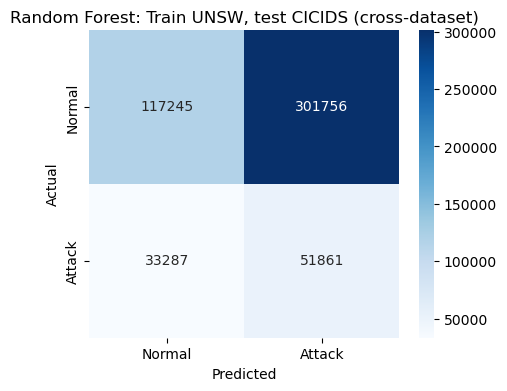

{'model': 'Random Forest',
 'experiment': 'Train UNSW, test CICIDS (cross-dataset)',
 'accuracy': 0.33542861336628654,
 'balanced_accuracy': 0.4444446249290461,
 'precision': 0.14665867308415603,
 'recall': 0.6090689153004181,
 'f1': 0.2363953369115586,
 'roc_auc': 0.3644625654396584,
 'train_seconds': 27.7,
 'predict_seconds': 1.2254}

In [9]:
# Cross-dataset: train UNSW harmonized, test CICIDS harmonized
evaluate_and_record(rf_unsw_harm, X_cic_test_harm, y_cic_test_harm, "Random Forest", "Train UNSW, test CICIDS (cross-dataset)", t_unsw_harm)

Random Forest - Train CICIDS, test UNSW (cross-dataset)
  accuracy          : 0.4494
  balanced_accuracy : 0.5
  precision         : 0.0
  recall            : 0.0
  f1                : 0.0
  roc_auc           : 0.3939
  train time (s)    : 415.0

              precision    recall  f1-score   support

      Normal       0.45      1.00      0.62     37000
      Attack       0.00      0.00      0.00     45332

    accuracy                           0.45     82332
   macro avg       0.22      0.50      0.31     82332
weighted avg       0.20      0.45      0.28     82332



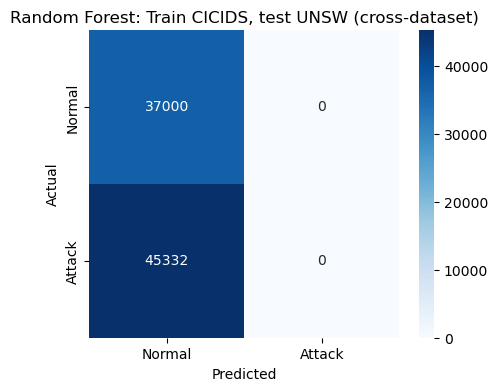

{'model': 'Random Forest',
 'experiment': 'Train CICIDS, test UNSW (cross-dataset)',
 'accuracy': 0.44939999028324346,
 'balanced_accuracy': 0.5,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.39388346636586286,
 'train_seconds': 415.0,
 'predict_seconds': 1.2988}

In [10]:
# Cross-dataset: train CICIDS harmonized, test UNSW harmonized
evaluate_and_record(rf_cic_harm, X_unsw_test_harm, y_unsw_test_harm, "Random Forest", "Train CICIDS, test UNSW (cross-dataset)", t_cic_harm)

# 5. XGBoost

Same experiment structure as Random Forest. `tree_method='hist'` for speed on CICIDS's larger training set. No feature scaling needed.

XGBoost - UNSW full features (within-dataset)
  accuracy          : 0.8664
  balanced_accuracy : 0.8549
  precision         : 0.8209
  recall            : 0.9686
  f1                : 0.8887
  roc_auc           : 0.9779
  train time (s)    : 2.42

              precision    recall  f1-score   support

      Normal       0.95      0.74      0.83     37000
      Attack       0.82      0.97      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.89      0.85      0.86     82332
weighted avg       0.88      0.87      0.86     82332



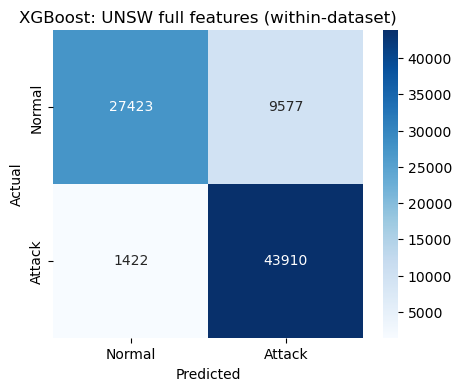

{'model': 'XGBoost',
 'experiment': 'UNSW full features (within-dataset)',
 'accuracy': 0.8664067434290433,
 'balanced_accuracy': 0.8548967962491743,
 'precision': 0.8209471460354852,
 'recall': 0.9686314303361864,
 'f1': 0.8886954937815602,
 'roc_auc': 0.9778515954960519,
 'train_seconds': 2.42,
 'predict_seconds': 0.3182}

In [11]:
xgb_settings = dict(n_estimators=100, random_state=RANDOM_STATE, tree_method="hist", eval_metric="logloss", n_jobs=-1)

t0 = time.time()
xgb_unsw = XGBClassifier(**xgb_settings)
xgb_unsw.fit(X_unsw_train, y_unsw_train)
t_unsw = time.time() - t0
evaluate_and_record(xgb_unsw, X_unsw_test, y_unsw_test, "XGBoost", "UNSW full features (within-dataset)", t_unsw)

XGBoost - CICIDS full features (within-dataset)
  accuracy          : 0.9992
  balanced_accuracy : 0.9989
  precision         : 0.9966
  recall            : 0.9986
  f1                : 0.9976
  roc_auc           : 1.0
  train time (s)    : 29.45

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    419001
      Attack       1.00      1.00      1.00     85148

    accuracy                           1.00    504149
   macro avg       1.00      1.00      1.00    504149
weighted avg       1.00      1.00      1.00    504149



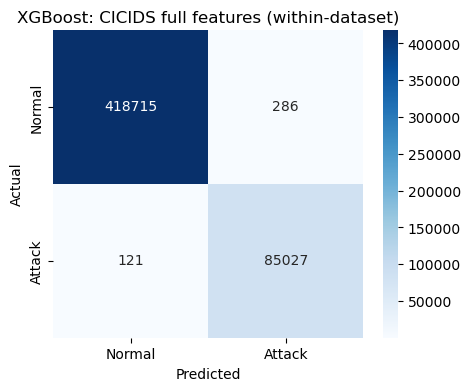

{'model': 'XGBoost',
 'experiment': 'CICIDS full features (within-dataset)',
 'accuracy': 0.9991926989838321,
 'balanced_accuracy': 0.9989481844796865,
 'precision': 0.9966476386951578,
 'recall': 0.9985789448959459,
 'f1': 0.9976123570787454,
 'roc_auc': 0.9999790301044702,
 'train_seconds': 29.45,
 'predict_seconds': 0.9673}

In [12]:
t0 = time.time()
xgb_cic = XGBClassifier(**xgb_settings)
xgb_cic.fit(X_cic_train, y_cic_train)
t_cic = time.time() - t0
evaluate_and_record(xgb_cic, X_cic_test, y_cic_test, "XGBoost", "CICIDS full features (within-dataset)", t_cic)

XGBoost - UNSW harmonized (within-dataset)
  accuracy          : 0.8636
  balanced_accuracy : 0.8506
  precision         : 0.8122
  recall            : 0.9785
  f1                : 0.8876
  roc_auc           : 0.9787
  train time (s)    : 1.8

              precision    recall  f1-score   support

      Normal       0.96      0.72      0.83     37000
      Attack       0.81      0.98      0.89     45332

    accuracy                           0.86     82332
   macro avg       0.89      0.85      0.86     82332
weighted avg       0.88      0.86      0.86     82332



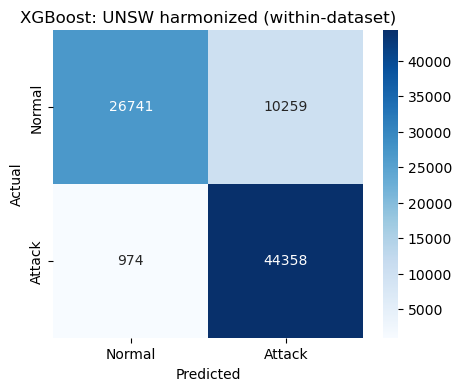

{'model': 'XGBoost',
 'experiment': 'UNSW harmonized (within-dataset)',
 'accuracy': 0.8635645921391439,
 'balanced_accuracy': 0.8506219018365405,
 'precision': 0.8121647106212352,
 'recall': 0.9785140739433513,
 'f1': 0.8876126824680588,
 'roc_auc': 0.9786608347185093,
 'train_seconds': 1.8,
 'predict_seconds': 0.4505}

In [13]:
t0 = time.time()
xgb_unsw_harm = XGBClassifier(**xgb_settings)
xgb_unsw_harm.fit(X_unsw_train_harm, y_unsw_train_harm)
t_unsw_harm = time.time() - t0
evaluate_and_record(xgb_unsw_harm, X_unsw_test_harm, y_unsw_test_harm, "XGBoost", "UNSW harmonized (within-dataset)", t_unsw_harm)

XGBoost - CICIDS harmonized (within-dataset)
  accuracy          : 0.9962
  balanced_accuracy : 0.9918
  precision         : 0.9925
  recall            : 0.9851
  f1                : 0.9888
  roc_auc           : 0.9996
  train time (s)    : 14.61

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    419001
      Attack       0.99      0.99      0.99     85148

    accuracy                           1.00    504149
   macro avg       0.99      0.99      0.99    504149
weighted avg       1.00      1.00      1.00    504149



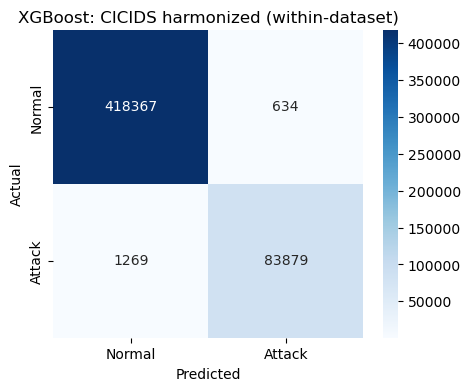

{'model': 'XGBoost',
 'experiment': 'CICIDS harmonized (within-dataset)',
 'accuracy': 0.9962253222757558,
 'balanced_accuracy': 0.9917917074563221,
 'precision': 0.9924981955438809,
 'recall': 0.9850965377930192,
 'f1': 0.9887835153629887,
 'roc_auc': 0.9996276220863797,
 'train_seconds': 14.61,
 'predict_seconds': 1.4064}

In [14]:
t0 = time.time()
xgb_cic_harm = XGBClassifier(**xgb_settings)
xgb_cic_harm.fit(X_cic_train_harm, y_cic_train_harm)
t_cic_harm = time.time() - t0
evaluate_and_record(xgb_cic_harm, X_cic_test_harm, y_cic_test_harm, "XGBoost", "CICIDS harmonized (within-dataset)", t_cic_harm)

XGBoost - Train UNSW, test CICIDS (cross-dataset)
  accuracy          : 0.4067
  balanced_accuracy : 0.4552
  precision         : 0.1481
  recall            : 0.5286
  f1                : 0.2313
  roc_auc           : 0.396
  train time (s)    : 1.8

              precision    recall  f1-score   support

      Normal       0.80      0.38      0.52    419001
      Attack       0.15      0.53      0.23     85148

    accuracy                           0.41    504149
   macro avg       0.47      0.46      0.37    504149
weighted avg       0.69      0.41      0.47    504149



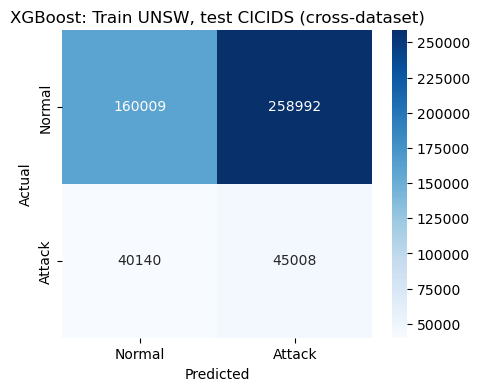

{'model': 'XGBoost',
 'experiment': 'Train UNSW, test CICIDS (cross-dataset)',
 'accuracy': 0.40665953914418157,
 'balanced_accuracy': 0.4552338325796349,
 'precision': 0.14805263157894738,
 'recall': 0.5285855216798986,
 'f1': 0.23131559201126567,
 'roc_auc': 0.39597294382993115,
 'train_seconds': 1.8,
 'predict_seconds': 1.3848}

In [15]:
evaluate_and_record(xgb_unsw_harm, X_cic_test_harm, y_cic_test_harm, "XGBoost", "Train UNSW, test CICIDS (cross-dataset)", t_unsw_harm)

XGBoost - Train CICIDS, test UNSW (cross-dataset)
  accuracy          : 0.4498
  balanced_accuracy : 0.5004
  precision         : 0.95
  recall            : 0.0008
  f1                : 0.0017
  roc_auc           : 0.6586
  train time (s)    : 14.61

              precision    recall  f1-score   support

      Normal       0.45      1.00      0.62     37000
      Attack       0.95      0.00      0.00     45332

    accuracy                           0.45     82332
   macro avg       0.70      0.50      0.31     82332
weighted avg       0.73      0.45      0.28     82332



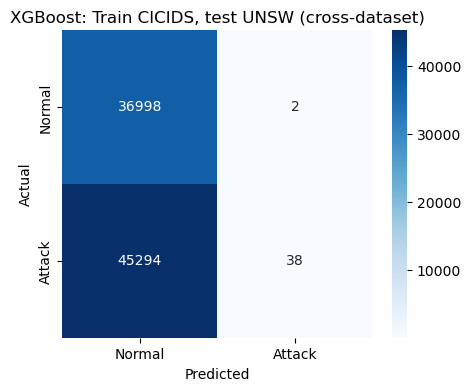

{'model': 'XGBoost',
 'experiment': 'Train CICIDS, test UNSW (cross-dataset)',
 'accuracy': 0.4498372443278434,
 'balanced_accuracy': 0.500392102947384,
 'precision': 0.95,
 'recall': 0.0008382599488220241,
 'f1': 0.0016750418760469012,
 'roc_auc': 0.6586226062491504,
 'train_seconds': 14.61,
 'predict_seconds': 0.1313}

In [16]:
evaluate_and_record(xgb_cic_harm, X_unsw_test_harm, y_unsw_test_harm, "XGBoost", "Train CICIDS, test UNSW (cross-dataset)", t_cic_harm)

# 6. Support Vector Machine

SVM needs scaled features, and its training cost scales poorly with row
count (`SVC` is roughly quadratic-to-cubic in the number of training rows).
Training on the full CICIDS2017 training set (465k+ rows) in this notebook
would take an impractically long time for a single comparison run.

**Computational decision (documented, not silent):** every SVM training run
in this notebook uses a **stratified random subsample of 20,000 training
rows**, applied uniformly to every SVM experiment (not just the large ones)
so the comparison across datasets stays apples-to-apples. The **test sets
are never subsampled** — final evaluation always uses the full, untouched
test set, same as every other model in this notebook. This is the same
"necessary practical shortcut, not a rigor shortcut" reasoning used for the
hyperparameter-search subsamples in the original project's Random
Forest/XGBoost notebooks, just applied to training itself rather than only
to a parameter search.

In [17]:
SVM_TRAIN_SAMPLE_SIZE = 20000

def stratified_subsample(X, y, size, random_state=RANDOM_STATE):
    if len(X) <= size:
        return X, y
    X_sub, _, y_sub, _ = train_test_split(X, y, train_size=size, stratify=y, random_state=random_state)
    return X_sub, y_sub

print(f"SVM training subsample size: {SVM_TRAIN_SAMPLE_SIZE} rows (test sets stay full-size).")

SVM training subsample size: 20000 rows (test sets stay full-size).


In [18]:
# Scale features for SVM - fit on the (subsampled) training data only, never on test data
unsw_svm_scaler = StandardScaler()
X_unsw_train_sub, y_unsw_train_sub = stratified_subsample(X_unsw_train, y_unsw_train, SVM_TRAIN_SAMPLE_SIZE)
X_unsw_train_sub_scaled = unsw_svm_scaler.fit_transform(X_unsw_train_sub)
X_unsw_test_scaled_svm = unsw_svm_scaler.transform(X_unsw_test)

cic_svm_scaler = StandardScaler()
X_cic_train_sub, y_cic_train_sub = stratified_subsample(X_cic_train, y_cic_train, SVM_TRAIN_SAMPLE_SIZE)
X_cic_train_sub_scaled = cic_svm_scaler.fit_transform(X_cic_train_sub)
X_cic_test_scaled_svm = cic_svm_scaler.transform(X_cic_test)

print("UNSW SVM training subsample:", X_unsw_train_sub.shape, " class balance:", y_unsw_train_sub.value_counts().to_dict())
print("CICIDS SVM training subsample:", X_cic_train_sub.shape, " class balance:", y_cic_train_sub.value_counts().to_dict())

UNSW SVM training subsample: (20000, 33)  class balance: {1: 13612, 0: 6388}
CICIDS SVM training subsample: (20000, 56)  class balance: {0: 16622, 1: 3378}


SVM - UNSW full features (within-dataset)
  accuracy          : 0.8148
  balanced_accuracy : 0.7946
  precision         : 0.7504
  recall            : 0.9944
  f1                : 0.8554
  roc_auc           : 0.9398
  train time (s)    : 18.75

              precision    recall  f1-score   support

      Normal       0.99      0.59      0.74     37000
      Attack       0.75      0.99      0.86     45332

    accuracy                           0.81     82332
   macro avg       0.87      0.79      0.80     82332
weighted avg       0.86      0.81      0.80     82332



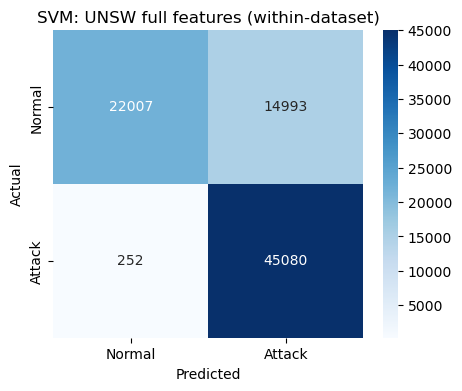

{'model': 'SVM',
 'experiment': 'UNSW full features (within-dataset)',
 'accuracy': 0.8148350580576204,
 'balanced_accuracy': 0.7946123983773767,
 'precision': 0.7504203219416377,
 'recall': 0.9944410129709698,
 'f1': 0.8553673924386889,
 'roc_auc': 0.9397693822274582,
 'train_seconds': 18.75,
 'predict_seconds': 37.1309}

In [19]:
t0 = time.time()
svm_unsw = SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
svm_unsw.fit(X_unsw_train_sub_scaled, y_unsw_train_sub)
t_unsw = time.time() - t0
evaluate_and_record(svm_unsw, X_unsw_test_scaled_svm, y_unsw_test, "SVM", "UNSW full features (within-dataset)", t_unsw)

SVM - CICIDS full features (within-dataset)
  accuracy          : 0.9657
  balanced_accuracy : 0.9328
  precision         : 0.9111
  recall            : 0.883
  f1                : 0.8968
  roc_auc           : 0.9897
  train time (s)    : 11.76

              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98    419001
      Attack       0.91      0.88      0.90     85148

    accuracy                           0.97    504149
   macro avg       0.94      0.93      0.94    504149
weighted avg       0.97      0.97      0.97    504149



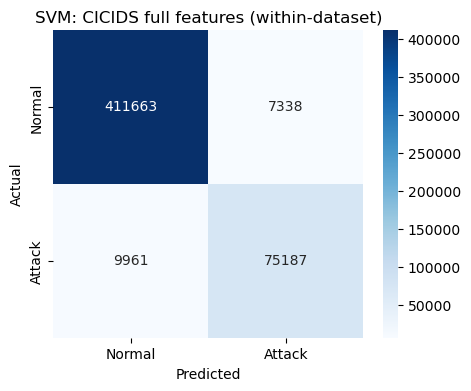

{'model': 'SVM',
 'experiment': 'CICIDS full features (within-dataset)',
 'accuracy': 0.9656867315019965,
 'balanced_accuracy': 0.93275118537399,
 'precision': 0.9110814904574371,
 'recall': 0.8830154554422888,
 'f1': 0.8968289468191063,
 'roc_auc': 0.9896772195346435,
 'train_seconds': 11.76,
 'predict_seconds': 192.7835}

In [20]:
t0 = time.time()
svm_cic = SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
svm_cic.fit(X_cic_train_sub_scaled, y_cic_train_sub)
t_cic = time.time() - t0
evaluate_and_record(svm_cic, X_cic_test_scaled_svm, y_cic_test, "SVM", "CICIDS full features (within-dataset)", t_cic)

SVM - UNSW harmonized (within-dataset)
  accuracy          : 0.7288
  balanced_accuracy : 0.7122
  precision         : 0.7038
  recall            : 0.8761
  f1                : 0.7806
  roc_auc           : 0.7964
  train time (s)    : 33.65

              precision    recall  f1-score   support

      Normal       0.78      0.55      0.65     37000
      Attack       0.70      0.88      0.78     45332

    accuracy                           0.73     82332
   macro avg       0.74      0.71      0.71     82332
weighted avg       0.74      0.73      0.72     82332



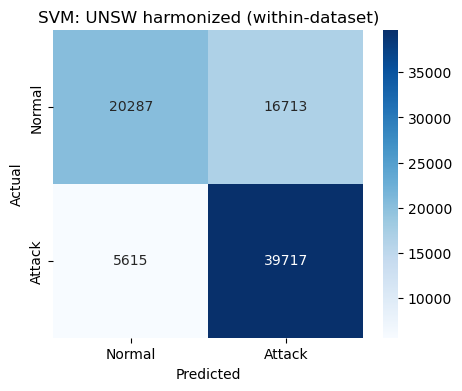

{'model': 'SVM',
 'experiment': 'UNSW harmonized (within-dataset)',
 'accuracy': 0.7288053247825875,
 'balanced_accuracy': 0.7122166800613372,
 'precision': 0.7038277511961722,
 'recall': 0.8761360628253773,
 'f1': 0.7805860733869224,
 'roc_auc': 0.7964027081877607,
 'train_seconds': 33.65,
 'predict_seconds': 82.8175}

In [21]:
# Harmonized features - same subsample + scaling approach
unsw_harm_svm_scaler = StandardScaler()
X_unsw_train_harm_sub, y_unsw_train_harm_sub = stratified_subsample(X_unsw_train_harm, y_unsw_train_harm, SVM_TRAIN_SAMPLE_SIZE)
X_unsw_train_harm_sub_scaled = unsw_harm_svm_scaler.fit_transform(X_unsw_train_harm_sub)
X_unsw_test_harm_scaled = unsw_harm_svm_scaler.transform(X_unsw_test_harm)

cic_harm_svm_scaler = StandardScaler()
X_cic_train_harm_sub, y_cic_train_harm_sub = stratified_subsample(X_cic_train_harm, y_cic_train_harm, SVM_TRAIN_SAMPLE_SIZE)
X_cic_train_harm_sub_scaled = cic_harm_svm_scaler.fit_transform(X_cic_train_harm_sub)
X_cic_test_harm_scaled = cic_harm_svm_scaler.transform(X_cic_test_harm)

t0 = time.time()
svm_unsw_harm = SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
svm_unsw_harm.fit(X_unsw_train_harm_sub_scaled, y_unsw_train_harm_sub)
t_unsw_harm = time.time() - t0
evaluate_and_record(svm_unsw_harm, X_unsw_test_harm_scaled, y_unsw_test_harm, "SVM", "UNSW harmonized (within-dataset)", t_unsw_harm)

SVM - CICIDS harmonized (within-dataset)
  accuracy          : 0.9264
  balanced_accuracy : 0.7836
  precision         : 0.9938
  recall            : 0.568
  f1                : 0.7228
  roc_auc           : 0.9414
  train time (s)    : 17.48

              precision    recall  f1-score   support

      Normal       0.92      1.00      0.96    419001
      Attack       0.99      0.57      0.72     85148

    accuracy                           0.93    504149
   macro avg       0.96      0.78      0.84    504149
weighted avg       0.93      0.93      0.92    504149



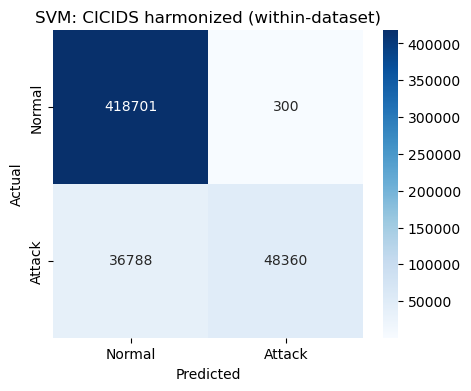

{'model': 'SVM',
 'experiment': 'CICIDS harmonized (within-dataset)',
 'accuracy': 0.9264344469591331,
 'balanced_accuracy': 0.7836181412973291,
 'precision': 0.9938347718865598,
 'recall': 0.567952271339315,
 'f1': 0.7228267368169318,
 'roc_auc': 0.941386378652804,
 'train_seconds': 17.48,
 'predict_seconds': 216.9793}

In [22]:
t0 = time.time()
svm_cic_harm = SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
svm_cic_harm.fit(X_cic_train_harm_sub_scaled, y_cic_train_harm_sub)
t_cic_harm = time.time() - t0
evaluate_and_record(svm_cic_harm, X_cic_test_harm_scaled, y_cic_test_harm, "SVM", "CICIDS harmonized (within-dataset)", t_cic_harm)

**Cross-dataset note:** the SVM trained on UNSW's harmonized features
was scaled using UNSW's own scaler; testing it on CICIDS requires
transforming CICIDS's test data with that *same* UNSW-fitted scaler — using
CICIDS's own scaler instead would silently re-introduce leakage-equivalent
information (CICIDS's own mean/std), defeating the point of the
cross-dataset test. The same logic applies in reverse.

SVM - Train UNSW, test CICIDS (cross-dataset)
  accuracy          : 0.6799
  balanced_accuracy : 0.7214
  precision         : 0.3183
  recall            : 0.784
  f1                : 0.4528
  roc_auc           : 0.7424
  train time (s)    : 33.65

              precision    recall  f1-score   support

      Normal       0.94      0.66      0.77    419001
      Attack       0.32      0.78      0.45     85148

    accuracy                           0.68    504149
   macro avg       0.63      0.72      0.61    504149
weighted avg       0.83      0.68      0.72    504149



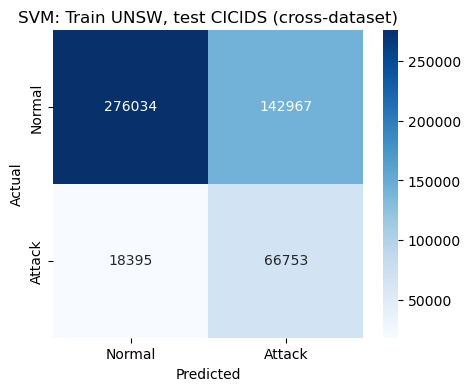

{'model': 'SVM',
 'experiment': 'Train UNSW, test CICIDS (cross-dataset)',
 'accuracy': 0.6799319248872853,
 'balanced_accuracy': 0.7213775909440199,
 'precision': 0.318295823002098,
 'recall': 0.7839643914125992,
 'f1': 0.45276530515349234,
 'roc_auc': 0.742380655750317,
 'train_seconds': 33.65,
 'predict_seconds': 491.9256}

In [23]:
# Cross-dataset: train UNSW harmonized, test CICIDS harmonized (scaled with the UNSW-fitted scaler)
X_cic_test_harm_scaled_with_unsw_scaler = unsw_harm_svm_scaler.transform(X_cic_test_harm)
evaluate_and_record(svm_unsw_harm, X_cic_test_harm_scaled_with_unsw_scaler, y_cic_test_harm, "SVM", "Train UNSW, test CICIDS (cross-dataset)", t_unsw_harm)

SVM - Train CICIDS, test UNSW (cross-dataset)
  accuracy          : 0.4494
  balanced_accuracy : 0.5
  precision         : 0.0
  recall            : 0.0
  f1                : 0.0
  roc_auc           : 0.577
  train time (s)    : 17.48

              precision    recall  f1-score   support

      Normal       0.45      1.00      0.62     37000
      Attack       0.00      0.00      0.00     45332

    accuracy                           0.45     82332
   macro avg       0.22      0.50      0.31     82332
weighted avg       0.20      0.45      0.28     82332



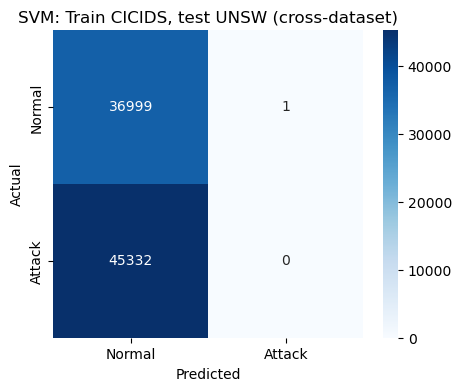

{'model': 'SVM',
 'experiment': 'Train CICIDS, test UNSW (cross-dataset)',
 'accuracy': 0.4493878443375601,
 'balanced_accuracy': 0.49998648648648647,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.5770331401837733,
 'train_seconds': 17.48,
 'predict_seconds': 31.9066}

In [24]:
# Cross-dataset: train CICIDS harmonized, test UNSW harmonized (scaled with the CICIDS-fitted scaler)
X_unsw_test_harm_scaled_with_cic_scaler = cic_harm_svm_scaler.transform(X_unsw_test_harm)
evaluate_and_record(svm_cic_harm, X_unsw_test_harm_scaled_with_cic_scaler, y_unsw_test_harm, "SVM", "Train CICIDS, test UNSW (cross-dataset)", t_cic_harm)

# 7. Combined Results Table

In [25]:
results_df = pd.DataFrame(all_results)
results_df.to_csv(os.path.join(PROCESSED_DIR, "classical_ml_results.csv"), index=False)

pd.set_option("display.max_columns", None)
results_df

,model,experiment,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,train_seconds,predict_seconds
0,Random Forest,UNSW full features (within-dataset),0.865812,0.853934,0.818755,0.971301,0.888528,0.975194,48.99,2.1052
1,Random Forest,CICIDS full features (within-dataset),0.998615,0.997324,0.996426,0.995373,0.995899,0.999773,837.62,12.8743
2,Random Forest,UNSW harmonized (within-dataset),0.868423,0.857443,0.824990,0.965940,0.889919,0.964721,27.70,2.2116
3,Random Forest,CICIDS harmonized (within-dataset),0.995565,0.991759,0.987706,0.986013,0.986859,0.997332,415.00,11.5299
4,Random Forest,"Train UNSW, test CICIDS (cross-dataset)",0.335429,0.444445,0.146659,0.609069,0.236395,0.364463,27.70,1.2254
5,Random Forest,"Train CICIDS, test UNSW (cross-dataset)",0.449400,0.500000,0.000000,0.000000,0.000000,0.393883,415.00,1.2988
6,XGBoost,UNSW full features (within-dataset),0.866407,0.854897,0.820947,0.968631,0.888695,0.977852,2.42,0.3182
7,XGBoost,CICIDS full features (within-dataset),0.999193,0.998948,0.996648,0.998579,0.997612,0.999979,29.45,0.9673
8,XGBoost,UNSW harmonized (within-dataset),0.863565,0.850622,0.812165,0.978514,0.887613,0.978661,1.80,0.4505
9,XGBoost,CICIDS harmonized (within-dataset),0.996225,0.991792,0.992498,0.985097,0.988784,0.999628,14.61,1.4064


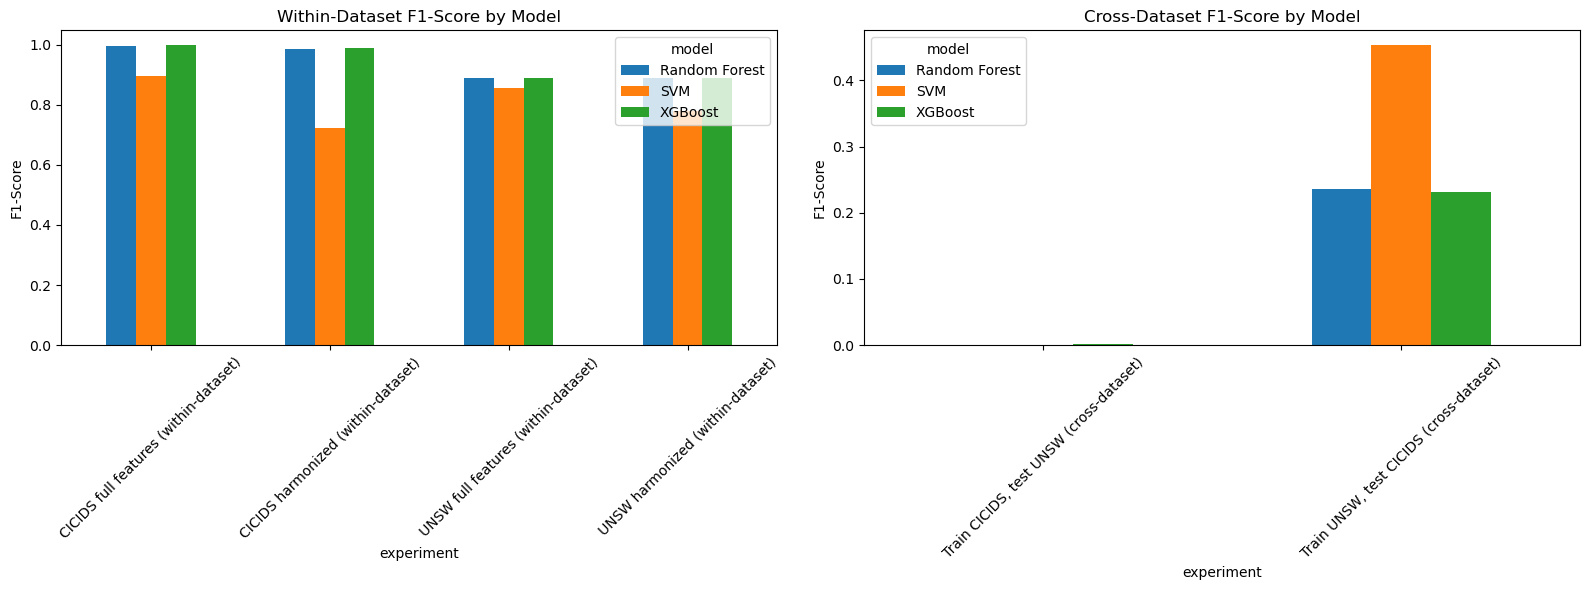

In [26]:
metric_cols = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

within_mask = results_df["experiment"].str.contains("within-dataset")
cross_mask = results_df["experiment"].str.contains("cross-dataset")

pivot_within = results_df[within_mask].pivot(index="experiment", columns="model", values="f1")
pivot_within.plot(kind="bar", ax=axes[0])
axes[0].set_title("Within-Dataset F1-Score by Model")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis="x", rotation=45)

pivot_cross = results_df[cross_mask].pivot(index="experiment", columns="model", values="f1")
pivot_cross.plot(kind="bar", ax=axes[1])
axes[1].set_title("Cross-Dataset F1-Score by Model")
axes[1].set_ylabel("F1-Score")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# 8. Saving Models

Models fitted on the **full-feature, within-dataset** training sets are
saved for reuse in Notebook 6 (explainability) and Notebook 7 (final
integration) — this avoids retraining in later notebooks and guarantees
those notebooks explain/evaluate the exact models reported here.

In [27]:
import joblib

joblib.dump(rf_unsw, os.path.join(MODELS_DIR, "rf_unsw_full.joblib"))
joblib.dump(rf_cic, os.path.join(MODELS_DIR, "rf_cic_full.joblib"))
joblib.dump(xgb_unsw, os.path.join(MODELS_DIR, "xgb_unsw_full.joblib"))
joblib.dump(xgb_cic, os.path.join(MODELS_DIR, "xgb_cic_full.joblib"))
joblib.dump(svm_unsw, os.path.join(MODELS_DIR, "svm_unsw_full.joblib"))
joblib.dump(svm_cic, os.path.join(MODELS_DIR, "svm_cic_full.joblib"))
joblib.dump(unsw_svm_scaler, os.path.join(MODELS_DIR, "unsw_svm_scaler.joblib"))
joblib.dump(cic_svm_scaler, os.path.join(MODELS_DIR, "cic_svm_scaler.joblib"))

print("Models and SVM scalers saved to", MODELS_DIR)

Models and SVM scalers saved to C:\Users\Anu\OneDrive\Desktop\IDS\models


# 9. Summary

PLACEHOLDER_SUMMARY